In [1]:
# Day 20: Student Performance Prediction System

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Student Performance Prediction System")
print("Day 20 - Student Marks Prediction")

Student Performance Prediction System
Day 20 - Student Marks Prediction


In [2]:
# Step 2: Create Student Dataset

data = {
    "Study_Hours": [2, 3, 4, 5, 6, 1, 7, 8, 3, 5, 6, 2, 9, 4, 7],
    "Attendance": [60, 70, 75, 80, 85, 50, 90, 95, 65, 78, 88, 55, 98, 72, 92],
    "Previous_Marks": [45, 50, 55, 60, 65, 35, 75, 85, 48, 62, 70, 40, 90, 58, 80],
    "Final_Marks": [48, 52, 58, 65, 70, 38, 78, 88, 50, 64, 73, 42, 94, 60, 83]
}

df = pd.DataFrame(data)

print("Student Dataset:")
display(df.head(10))

print("\nDataset Shape:", df.shape)

Student Dataset:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,2,60,45,48
1,3,70,50,52
2,4,75,55,58
3,5,80,60,65
4,6,85,65,70
5,1,50,35,38
6,7,90,75,78
7,8,95,85,88
8,3,65,48,50
9,5,78,62,64



Dataset Shape: (15, 4)


In [3]:
# Step 3: Separate Features and Target Variable

X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Final_Marks"]

print("Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Features (X):


,Study_Hours,Attendance,Previous_Marks
0,2,60,45
1,3,70,50
2,4,75,55
3,5,80,60
4,6,85,65



Target Variable (y):


0    48
1    52
2    58
3    65
4    70
Name: Final_Marks, dtype: int64


Features Shape: (15, 3)
Target Shape: (15,)


In [4]:
# Step 4: Split Data into Training and Testing Sets

np.random.seed(42)

indices = np.random.permutation(len(X))

test_size = 3
test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Data Shape: (12, 3)
Testing Data Shape: (3, 3)

Training Samples: 12
Testing Samples: 3


In [5]:
# Step 5: Train Linear Regression Model

# Add intercept column
X_train_array = X_train.to_numpy(dtype=float)
X_test_array = X_test.to_numpy(dtype=float)

X_train_bias = np.column_stack([
    np.ones(len(X_train_array)),
    X_train_array
])

X_test_bias = np.column_stack([
    np.ones(len(X_test_array)),
    X_test_array
])

# Train the model using least squares
linear_coefficients = np.linalg.lstsq(
    X_train_bias,
    y_train.to_numpy(dtype=float),
    rcond=None
)[0]

print("Linear Regression Model Trained Successfully!")
print("Model Coefficients:", linear_coefficients)

Linear Regression Model Trained Successfully!
Model Coefficients: [ 1.15949442e+01  2.48246662e+00 -3.89630671e-03  6.70824549e-01]


In [6]:
# Step 6: Predict Student Final Marks

y_pred = X_test_bias @ linear_coefficients

prediction_results = pd.DataFrame({
    "Actual_Marks": y_test.to_numpy(),
    "Predicted_Marks": np.round(y_pred, 2)
})

print("Student Marks Prediction Results:")
display(prediction_results)

Student Marks Prediction Results:


,Actual_Marks,Predicted_Marks
0,64,65.29
1,42,43.18
2,48,46.51


In [7]:
# Step 7: Evaluate Linear Regression Model

actual = y_test.to_numpy(dtype=float)
predicted = y_pred

mae = np.mean(np.abs(actual - predicted))
mse = np.mean((actual - predicted) ** 2)
rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1.32
Mean Squared Error (MSE): 1.76
Root Mean Squared Error (RMSE): 1.33


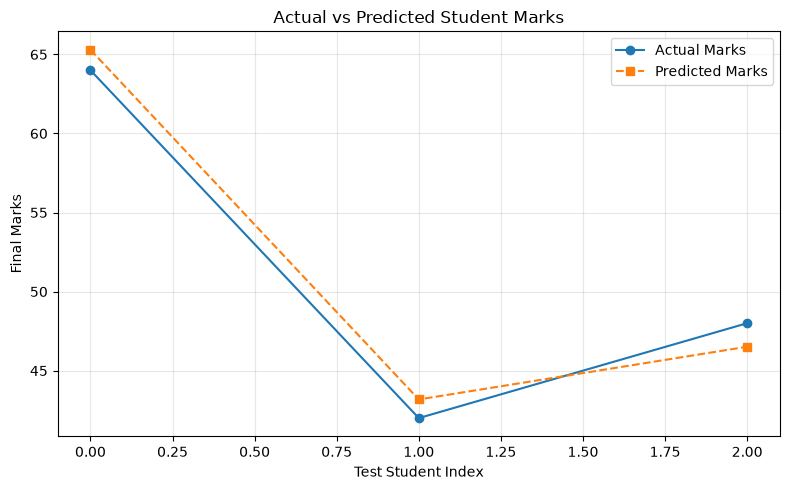

In [8]:
# Step 8: Visualize Actual vs Predicted Marks

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(actual)),
    actual,
    marker="o",
    label="Actual Marks"
)

plt.plot(
    range(len(predicted)),
    predicted,
    marker="s",
    linestyle="--",
    label="Predicted Marks"
)

plt.xlabel("Test Student Index")
plt.ylabel("Final Marks")
plt.title("Actual vs Predicted Student Marks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Step 9: Predict Marks for a New Student

# Example student details
study_hours = 6
attendance = 85
previous_marks = 70

new_student = np.array([
    1,
    study_hours,
    attendance,
    previous_marks
], dtype=float)

predicted_marks = new_student @ linear_coefficients

# Marks are expected to be within 0–100
predicted_marks = np.clip(predicted_marks, 0, 100)

print("New Student Details")
print("-------------------")
print("Study Hours:", study_hours)
print("Attendance:", attendance, "%")
print("Previous Marks:", previous_marks)

print("\nPredicted Final Marks:", round(predicted_marks, 2))

New Student Details
-------------------
Study Hours: 6
Attendance: 85 %
Previous Marks: 70

Predicted Final Marks: 73.12


In [10]:
# Step 10: Save Prediction Report

prediction_results["Absolute_Error"] = np.abs(actual - predicted).round(2)

report_file = "day20_student_performance_report.csv"
prediction_results.to_csv(report_file, index=False)

print("Prediction report saved successfully!")
print("File Name:", report_file)

print("\nReport Preview:")
display(prediction_results)

Prediction report saved successfully!
File Name: day20_student_performance_report.csv

Report Preview:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49


In [11]:
# Step 11: Final Project Summary

print("=" * 50)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 20 - PROJECT SUMMARY")
print("=" * 50)

print("\nDataset Information")
print("Total Students:", len(df))
print("Input Features:", list(X.columns))
print("Target Variable: Final_Marks")

print("\nModel Information")
print("Algorithm: Linear Regression")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nModel Evaluation")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")

print("\nNew Student Prediction")
print(f"Predicted Final Marks: {predicted_marks:.2f}")

print("\nReport File:", report_file)
print("\nProject execution completed successfully!")
print("=" * 50)

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 20 - PROJECT SUMMARY

Dataset Information
Total Students: 15
Input Features: ['Study_Hours', 'Attendance', 'Previous_Marks']
Target Variable: Final_Marks

Model Information
Algorithm: Linear Regression
Training Samples: 12
Testing Samples: 3

Model Evaluation
MAE: 1.32
MSE: 1.76
RMSE: 1.33

New Student Prediction
Predicted Final Marks: 73.12

Report File: day20_student_performance_report.csv

Project execution completed successfully!
